In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.api import ExponentialSmoothing
from statsmodels.tsa.api import Holt
from statsmodels.tsa.api import SimpleExpSmoothing
from tqdm import  tqdm
import warnings
warnings.filterwarnings('ignore')
import os
os.chdir('E:/Machine_Learning/Datasets/')

In [2]:
df = pd.read_csv('daily-total-female-births-in-cal.csv')
df.head()

,Date,Daily total female births in California
0,01-01-1959,35
1,02-01-1959,32
2,03-01-1959,30
3,04-01-1959,31
4,05-01-1959,44


In [3]:
y = df['Daily total female births in California']

In [4]:
y_train = y.iloc[:-31]
y_test = y.iloc[-31:]
y_train.shape,y_test.shape

((334,), (31,))

### Simple Exponential smoothing

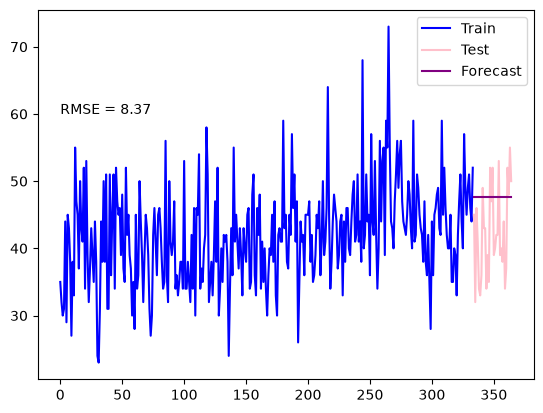

In [5]:
alpha = 0.2
ses = SimpleExpSmoothing(y_train, initialization_method='estimated')
fit1 = ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(0,60,f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


### Holt's Linear Trend (Additive):

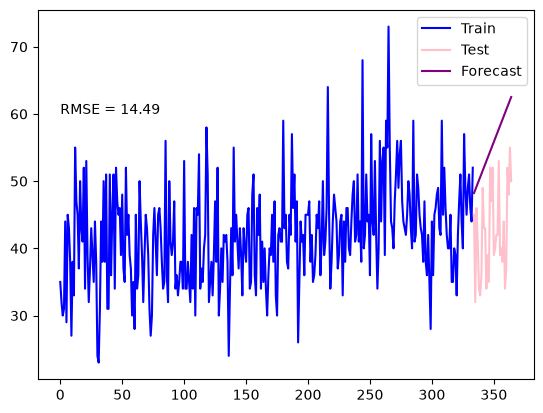

In [15]:
alpha,beta = 0.1,0.2
holt  = Holt(y_train, initialization_method='estimated')
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(00,60, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


### Holt's Exponential Trend (Multiplicative):

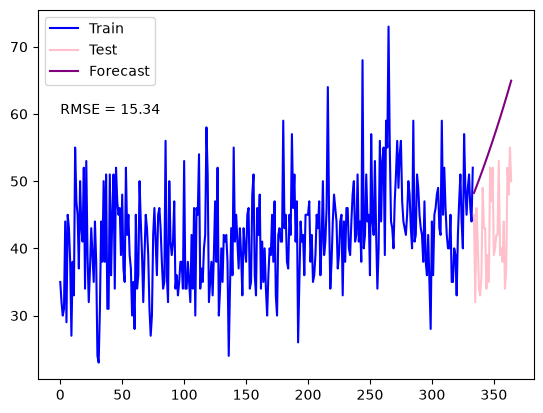

In [7]:
alpha,beta = 0.1,0.2
holt  = Holt(y_train, initialization_method='estimated',exponential=True) # just write exponential = True
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(0,60, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


### damped trend (Holt's)

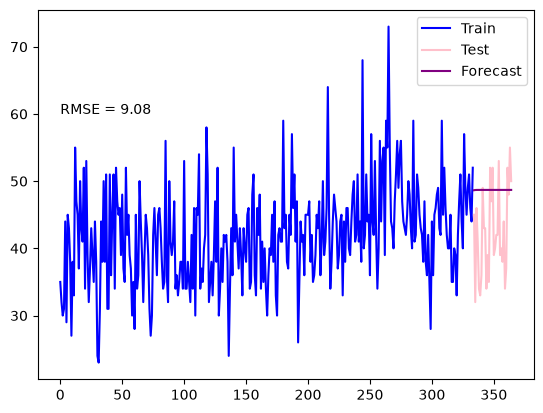

In [8]:
alpha,beta ,phi= 0.4,0.2,0.3
holt  = Holt(y_train, initialization_method='estimated',damped_trend=True) 
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(0,60, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


## Damped Exponential (Holt's)

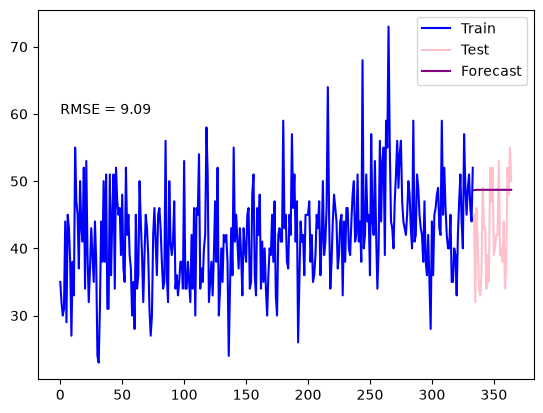

In [9]:
alpha,beta ,phi= 0.4,0.2,0.3
holt  = Holt(y_train, initialization_method='estimated',damped_trend=True,exponential=True) 
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(00,60, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


## Holt's Seasonal Exponential

In [13]:
alpha = np.linspace(0.01,0.99,10)
beta = np.linspace(0.01,0.99,10)
gamma = np.linspace(0.01,0.99,10)
scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            hw_add = ExponentialSmoothing(y_train,seasonal_periods=7,trend = 'add',seasonal = 'add')
            fit1 = hw_add.fit(smoothing_level = a ,smoothing_trend = b ,smoothing_seasonal = g)
            fcast1 = fit1.forecast(len(y_test))
            scores.append([a,b,g,root_mean_squared_error(y_test,fcast1)])

df_scores = pd.DataFrame(scores,columns=['alpha','beta','gamma','score'])
df_scores.sort_values('score',ascending=True)

100%|██████████| 10/10 [00:51<00:00,  5.18s/it]


,alpha,beta,gamma,score
50,0.010000,0.554444,0.010000,6.157738e+00
41,0.010000,0.445556,0.118889,6.379192e+00
40,0.010000,0.445556,0.010000,6.662452e+00
32,0.010000,0.336667,0.227778,6.749323e+00
10,0.010000,0.118889,0.010000,6.824506e+00
...,...,...,...,...
898,0.881111,0.990000,0.881111,9.598577e+08
899,0.881111,0.990000,0.990000,4.989587e+09
998,0.990000,0.990000,0.881111,6.286137e+09
989,0.990000,0.881111,0.990000,1.500244e+10


### adding one more parameter - seasonslity

In [14]:
alpha = np.linspace(0.01,0.99,10)
beta = np.linspace(0.01,0.99,10)
gamma = np.linspace(0.01,0.99,10)
scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            for s in ['add','mul']:
                hw_add = ExponentialSmoothing(y_train,seasonal_periods=7,trend = 'add',seasonal = s)
                fit1 = hw_add.fit(smoothing_level = a ,smoothing_trend = b ,smoothing_seasonal = g)
                fcast1 = fit1.forecast(len(y_test))
                scores.append([s,a,b,g,root_mean_squared_error(y_test,fcast1)])

df_scores = pd.DataFrame(scores,columns=['seasonality','alpha','beta','gamma','score'])
df_scores.sort_values('score',ascending=True)

100%|██████████| 10/10 [01:40<00:00, 10.07s/it]


,seasonality,alpha,beta,gamma,score
100,add,0.010000,0.554444,0.010000,6.157738e+00
101,mul,0.010000,0.554444,0.010000,6.226750e+00
83,mul,0.010000,0.445556,0.118889,6.340684e+00
82,add,0.010000,0.445556,0.118889,6.379192e+00
81,mul,0.010000,0.445556,0.010000,6.603226e+00
...,...,...,...,...,...
1796,add,0.881111,0.990000,0.881111,9.598577e+08
1798,add,0.881111,0.990000,0.990000,4.989587e+09
1996,add,0.990000,0.990000,0.881111,6.286137e+09
1978,add,0.990000,0.881111,0.990000,1.500244e+10


### Best model

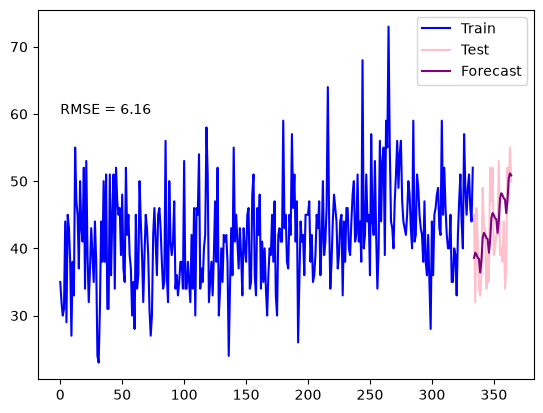

In [17]:
hw_add = ExponentialSmoothing(y_train,seasonal_periods=7,trend = 'add',seasonal = 'add')
fit1 = hw_add.fit(smoothing_level = 0.01 ,smoothing_trend = 0.554444 ,smoothing_seasonal = 0.01)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(00,60, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()
